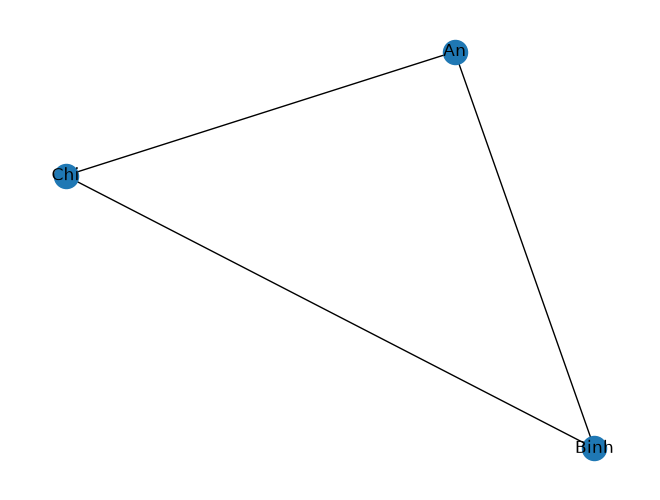

In [2]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()
G.add_edge("An", "Binh", weight=5)
G.add_edge("Binh", "Chi", weight=3)
G.add_edge("An", "Chi", weight=10)

nx.draw(G, with_labels=True)
plt.show()

In [3]:
km = float(input("Enter the distance in kilometers:"))
if km < 0:
    print("distance is not valid")
elif km < 2 and km >= 0:
    print("very close, can walk")
elif km >= 2 and km < 7:
    print("medium , ride a bike takes about 15 minutes")
else:
    print("far, take a car or bus")

medium , ride a bike takes about 15 minutes


In [4]:
def calculate_avg(numbers):
    sum = 0
    if len(numbers) == 0:
        return 0
    for n in numbers:
        sum+=n
    return sum/len(numbers)

ds_lat = [10.7769, 10.7820, 10.7626, 10.7950]
ds_lng = [106.7009, 106.6950, 106.6820, 106.7100]

lat = calculate_avg(ds_lat)
lng = calculate_avg(ds_lng)

print(f"Tọa độ trung tâm: ({lat:.4f}, {lng:.4f})")

Tọa độ trung tâm: (10.7791, 106.6970)


In [5]:
friends = {
    "An": (10.7769,106.7009),
    "Bình": (10.7820,106.6950),
    "Chi": (10.7626,106.6820),
    "Phi": (10.7950,106.7100)
}
lats = []
lngs = []

for ten,toa_do in friends.items():
    lats.append(toa_do[0])
    lngs.append(toa_do[1])
    
lat_avg = calculate_avg(lats)
lng_avg = calculate_avg(lngs)

ten = input("Nhập tên người dùng: ")
if ten in friends.keys():
    print(f"Tọa độ của {ten}: {friends[ten]}")
else:
    print(f"Không thấy người dùng")

print(f"Tọa độ trung tâm: ({lat_avg:.4f}, {lng_avg:.4f})")



Tọa độ của Chi: (10.7626, 106.682)
Tọa độ trung tâm: (10.7791, 106.6970)


- An: cách điểm hẹn 0.500 km -> very close, can walk
- Bình: cách điểm hẹn 0.384 km -> very close, can walk
- Chi: cách điểm hẹn 2.459 km -> medium, ride a bike takes about 15 minutes
- Phi: cách điểm hẹn 2.262 km -> medium, ride a bike takes about 15 minutes


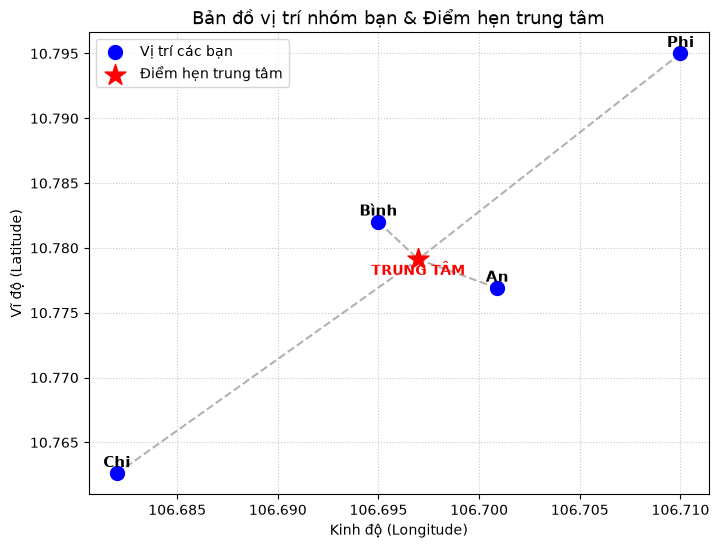

In [6]:
import math

def phan_loai(km):
    if km < 0:
        return "distance must not positive"
    elif km < 2:
        return "very close, can walk"
    elif km < 7:
        return "medium, ride a bike takes about 15 minutes"
    else:
        return "far, need to use a car or other transportation"
def calculate_avg(nums):
    sum_avg = 0
    for num in nums:
        sum_avg+=num
    return sum_avg/len(nums)
def distance(diem1,diem2):
    lat1,lng1 = diem1
    lat2,lng2 = diem2
    
    dx = (lng2 - lng1)*111.32
    dy = (lat2 - lat1)*111.32*math.cos(math.radians((lat1+lat2)/2))
    return math.sqrt(dy**2 + dx**2)

friends = {
    "An": (10.7769,106.7009),
    "Bình": (10.7820,106.6950),
    "Chi": (10.7626,106.6820),
    "Phi": (10.7950,106.7100)
}
lats = []
lngs = []

for ten,toa_do in friends.items():
    lats.append(toa_do[0])
    lngs.append(toa_do[1])
lat_avg = calculate_avg(lats)
lng_avg = calculate_avg(lngs)

toa_do_trung_tam = (lat_avg,lng_avg)

khoang_cach = []

for ten,toa_do in friends.items():
   print(f"- {ten}: cách điểm hẹn {distance(toa_do,toa_do_trung_tam):.3f} km -> {phan_loai(distance(toa_do,toa_do_trung_tam))}")

plt.figure(figsize=(8, 6))

# 1. Vẽ 4 người bạn (trục X là lngs, trục Y là lats)
plt.scatter(lngs, lats, color='blue', s=100, label='Vị trí các bạn', zorder=3)

# 2. Vẽ điểm hẹn trung tâm bằng ngôi sao đỏ
plt.scatter(lng_avg, lat_avg, color='red', marker='*', s=250, label='Điểm hẹn trung tâm', zorder=4)

# 3. Viết tên từng người và vẽ đường nối tới điểm trung tâm
for ten, (lat, lng) in friends.items():
    # Ghi tên lệch lên trên một chút (+0.0005) cho khỏi đè vào chấm tròn
    plt.text(lng, lat + 0.0005, ten, fontsize=11, fontweight='bold', ha='center')
    
    # Vẽ đường nét đứt nối từ người đó đến điểm trung tâm
    plt.plot([lng, lng_avg], [lat, lat_avg], color='gray', linestyle='--', alpha=0.6)

# Ghi nhãn cho điểm trung tâm
plt.text(lng_avg, lat_avg - 0.0012, "TRUNG TÂM", color='red', fontweight='bold', ha='center')

# 4. Trang trí tiêu đề, tên trục và lưới tọa độ
plt.title("Bản đồ vị trí nhóm bạn & Điểm hẹn trung tâm", fontsize=13)
plt.xlabel("Kinh độ (Longitude)")
plt.ylabel("Vĩ độ (Latitude)")
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend()

# Hiển thị biểu đồ
plt.show()